# Real In-Vivo Ultrasound Microvascular Mapping


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 观测到目标核查卡

当前存在 `data/raw_data.npz`；所述获取/估计路径由本地代码实现。

任务 `in_vivo_ultrasound_microvascular_mapping` 的观测定义：当前raw_data.npz的实际键、形状、dtype与README单位说明：iq (1, 30, 83, 128, 200) complex64：Measured complex IQ amplitude, arbitrary acquisition amplitude units; axes batch, block, axial position, lateral position, frame。恢复目标：microvascular density及平均speed，轨迹次数和acquisition pixel/s。

获取模型：IQ为组织clutter、microbubble PSF叠加与噪声；时间位置变化给血流。实际恢复算法：solvers.reconstruct：SVD滤波、physics_model.localize、Munkres关联、轨迹平滑/插值及渲染。语义类型为 `inverse_spatial`；其中闭式逆也属于反问题，但内部制造观测或缺输入的限制见下文。

真值情况：数值方法参考，不能当作独立物理真值；test/validation.md:102是原始double-radial方法density/speed，没有独立微血管真值。评估方法参考与仪器校准均不能当作独立物理真值。

现有实验和图：in_vivo_ultrasound_microvascular_mapping.ipynb单元6：5. Results；in_vivo_ultrasound_microvascular_mapping.ipynb单元7有保存图；图内容由该单元调用的本地visualization函数生成；in_vivo_ultrasound_microvascular_mapping.ipynb单元8有保存图；ax.set(title=title, xlabel='Lateral acquisition pixel', ylabel='Axial acquisition pixel')；axes[2].set(title='Actual central-pixel time series', xlabel='Time within block (s)', ylab；in_vivo_ultrasound_microvascular_mapping.ipynb单元11有保存图；图内容由该单元调用的本地visualization函数生成；in_vivo_ultrasound_microvascular_mapping.ipynb单元12有保存图；ax.set(title=title, xlabel='Lateral superpixel', ylabel='Axial superpixel')；axes[2].set(title='Occupied grid support, same accepted tracks', ylabel='Nonzero superpixels')；axes[row,；in_vivo_ultrasound_microvascular_mapping.ipynb单元13有保存图；axes[0].set(title='Track lengths: dashed upstream, solid fresh', xlabel='Observed positions per retained track', ylabel='Track count')；ax.set(title=label + ' summed-density spatial。图/比较代码位于单元7, 8, 11, 12, 13（从0计数）。代码单元8个，带execution_count的8个，保存PNG输出8幅；本审计未重新运行。

现有输出来自历史执行；本次未复跑。

限制与缺口：本次为静态语义与证据核查，未重新验证数值正确性或运行结果。

<!-- inverse-evidence-audit:20261026:end -->



## 1. Problem

Recover trajectory-crossing density and mean scalar path-speed maps from real in-vivo mouse-tumor IQ data. These two spatial outputs depend on localization, temporal association and finite bubble sampling; neither is independently known anatomical truth.

Maintainer reconstruction and scientific review. All three methods below actively process the same complete 30-block, 6000-frame mouse-tumor acquisition. The original implementation and fresh local results are identified separately. Density and speed are both reconstructed; no anatomical ground truth is asserted.


Microbubble contrast agents make it possible to image microcirculation beyond conventional ultrasound resolution by localizing individual acoustic responses and accumulating their trajectories. Here we infer the vascular organization and scalar path speed in an actual mouse mammary tumor. Strong tissue echoes obscure bubble responses; nearby bubbles overlap; a plausible spatial peak does not by itself establish a consistent circulating trajectory.

The unknowns are **a super-resolved trajectory-crossing density image and a scalar mean path-speed image**, each on an 831 by 1281 grid. The public input is already beamformed complex IQ, not channel RF. We use all 30 bound blocks and all 200 frames in each. Trajectories stop at block boundaries, because these acquisitions are intermittent.

This notebook asks whether the cleaned local mathematics reproduces the identified standard method and preserves its scientific comparisons. It does not treat method agreement as independently measured anatomical or hemodynamic truth.


## 2. Data

All 30 complete 83 by 128 by 200 complex64 blocks are retained, totaling 6000 frames at 500 Hz within blocks. IQ amplitude has acquisition units and speed remains native pixel/s because transducer pitch and wavelength do not independently calibrate the beamformed grid. Blocks are never temporally linked.


**Source and identity.** The data are the real **In Vivo Mouse Tumor** component of OPULM/PALA, version 1.1, [Zenodo DOI 10.5281/zenodo.4343435](https://doi.org/10.5281/zenodo.4343435). Specifically, these are complete `PALA_InVivoMouseTumor_001.mat` through `_030.mat` IQ blocks, drawn from the original 150-block experiment. This is distinct from the same deposit's simulated PSF and simulated-flow datasets. No synthetic observation, spatial crop, frame decimation, artificial noise, or downcast was introduced. ZIP-member lengths, CRC32 checks and SHA256 values are retained in validation; the entire 2.44 GB ZIP was not downloaded or claimed to have a verified whole-archive MD5.

The first 30 blocks provide 6000 measured frames, about 510 MB of uncompressed complex IQ. The data preserve the original complex64 values exactly. Only computation is promoted to complex128 for verified temporal-subspace stability. The archived transducer element pitch does not establish the beamformed image pixel spacing. Accordingly, coordinates and speeds remain acquisition pixel and acquisition pixel/s.

| Key | Shape | Dtype | Description |
| --- | --- | --- | --- |
| iq | (1, 30, 83, 128, 200) | complex64 | Measured IQ amplitude in arbitrary acquisition units; batch, block, axial, lateral, frame |

| Parameter | Value | Unit | Meaning |
| --- | --- | --- | --- |
| Intra-block frame rate | 500 | Hz | dt = 0.002 s |
| Block repetition | 2 | Hz | Separate intermittent bursts; do not connect trajectories across blocks |
| Frames per block | 200 | frame | Complete observed sequence |
| Native dimensions | 83 by 128 | acquisition pixel | Axial down, lateral right |
| Steering angles | -10, -5, 0, 5, 10 | degree | Five-angle compounding |
| Transmit frequency | 15 | MHz | Stored acquisition frequency |
| Receive setting | 60 | MHz | Stored receive frequency setting |
| Sampling frequency | 30 | MHz | Input has already been beamformed |
| Transducer pitch | 0.11 | mm | Element spacing, not an asserted IQ-grid spacing |
| Pulse length | 3 | cycle | Stored transmit setting |
| Absolute IQ-grid scale | independently unverified | mm/pixel | Speed is not labeled mm/s |
| Point response/noise variance | not separately calibrated | acquisition units | Local symmetry assumption; no hidden-target calibration |
| Spatial boundary | finite observed image | convention | No periodic extension or invented observations |

The dataset metadata and accompanying materials have differing CC BY / CC BY-NC-SA labels; the discrepancy and full required attributions are retained in `test/validation.md`. Local research use is not represented as unrestricted external redistribution.


In [1]:
import os
os.environ['OPENBLAS_NUM_THREADS'] = '1'
os.environ['OMP_NUM_THREADS'] = '1'
from pathlib import Path
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
assert (root / 'data/raw_data.npz').exists(), 'Run from task root or notebooks/'
os.chdir(root)
import sys, time, json
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.preprocessing import load_observations, preprocess_block
from src.solvers import reconstruct, METHODS
from src.visualization import metrics, plot_acquisition, plot_comparisons, plot_sampling
print('Task root:', root.name)
print('Numerical execution: CPU; one BLAS thread; complex128 computation from unchanged complex64 input')

Task root: in_vivo_ultrasound_microvascular_mapping
Numerical execution: CPU; one BLAS thread; complex128 computation from unchanged complex64 input


## 3. Physics

The beamformed model is $Y(r,t)=T(r,t)+\sum_ja_j(t)h(r-r_j(t))+\epsilon(r,t)$: $Y$ is complex IQ, $T$ tissue clutter, $a_j$ bubble amplitude, $h$ local response, $r_j$ bubble position and $\epsilon$ noise/model mismatch. Response symmetry supports localization without supplying a measured global PSF or an exact density-to-IQ inverse.


At position $r=(z,x)$ and time $t$, model the measured complex image as


$$
Y(r,t)=T(r,t)+\sum_{j=1}^{J(t)} a_j(t)h(r-r_j(t))+\epsilon(r,t).
$$


$Y$ is IQ amplitude, $T$ is tissue clutter, $J$ counts contributing bubbles, $a$ is complex scattering amplitude, $h$ is the local point response, $r_j$ is bubble position, and $\epsilon$ is noise/model mismatch. The small bubbles can be localized within broad responses, but this does not make the acoustic images themselves diffraction-free. Local magnitude symmetry supplies a position constraint; repeated positions over time supply trajectory evidence.

For one block, stack the 10624 spatial pixels into a complex matrix $X$ with 200 temporal columns, using column-major spatial order. The selected clutter separation decomposes $G=X^*X$ and retains temporal singular vectors 10 through 200, where $*$ means conjugate transpose. If $Q$ contains those vectors, the bubble-containing component is $(XQ)Q^*$. The first nine dominant temporal modes are rejected. There is no division by frame count or hidden clean target.

The native-single Gram problem is numerically sensitive because strong tissue dominates weak bubble components. A separate original-source single run is preserved; the selected runtime uses an explicitly identified double-computation variant on identical samples. Independent subspace checks establish a nonzero 9/10 gap, orthogonality, Hermitian/idempotent projection, and agreement between double LAPACK drivers. This is a precision exception, not a relaxed parity threshold.

Both tissue and bubbles can overlap in temporal frequency. The subsequent causal 25-249 Hz Butterworth bandpass helps suppress slow residual clutter but is not a perfect tissue/blood classifier. This is a phenomenological local-response and trajectory method, rather than a calibrated wave-equation inversion. Native pixel/s is therefore the scientifically supported speed unit.


## 4. Method

The local PALA path performs promoted-double tissue subspace filtering, causal bandpass filtering, radial localization, finite Munkres assignment, trajectory smoothing/interpolation and rendering. Weighted-average and integer-peak localization run as controls. Native-single instability, the verified double oracle and the rare fallback-sign issue remain separately documented.


**Detection and spatial inverse.** Exclude the source's three-pixel localization margin. Detect eight-connected regional maxima, retain magnitudes strictly above the frame's 201st masked value, and reject five-by-five ROIs with more than four maxima. There are at most 200 candidates per frame. The original unusual collapsed-dimension edge-zeroing statements and column-major candidate ordering are preserved explicitly.

For each ROI, diagonal finite differences $d_u=I(i,j+1)-I(i+1,j)$ and $d_v=I(i,j)-I(i+1,j+1)$ are averaged with a zero-extended three-by-three kernel, giving $f_u,f_v$. On midpoint coordinates $z,x$, define slope $m=-(f_v+f_u)/(f_u-f_v)$ and intercept $b=z-mx$. Let $g=f_u^2+f_v^2$, let $(z_0,x_0)$ be the $g$-weighted centroid, and let $w=g/\sqrt{(z-z_0)^2+(x-x_0)^2}$. Radial localization solves


$$
\min_{z_c,x_c}\sum_{i,j}\frac{w}{1+m^2}(z_c-mx_c-b)^2.
$$


This two-variable least-squares problem is evaluated directly using its normal equations. Positions outside the source's 1.5-pixel offset limit are rejected. Weighted-centroid and integer-offset comparisons use the same detections and rejection framework. The rare upstream unsmoothed-slope fallback has a sign discrepancy; it is explicitly investigated in validation, and no bound-data branch incidence is hidden.

**Assignment and temporal constraint.** For each adjacent pair of frames inside a block, form squared Euclidean position costs; edges farther than one native pixel are forbidden, while an exactly one-pixel edge is allowed. Remove rows and columns without valid edges. If $s$ is the sum of finite costs and $c$ their maximum, use forbidden replacement $10^{\lceil\log_{10}s\rceil+1}$ for $s>0$ (zero for $s=0$), and pad to a square with dummy cost $10c$. Minimize the complete padded assignment, then discard dummy and originally forbidden links. The all-zero case deliberately preserves the source's zero replacement cost; this is not an assertion of maximum-cardinality matching. An entirely invalid graph returns no links. The local Munkres implementation preserves upstream column-major tie rules. There is no gap closing and no association across blocks. Retain only trajectories strictly longer than eight observations.

**Trajectory and flow measurement.** Apply MATLAB default moving-average smoothing with requested span 20, which becomes odd span 19 when sufficiently long; endpoint windows shrink symmetrically. Interpolate linearly at original-frame abscissae $1,1+0.08,1+2(0.08),\ldots\leq n$, where $n$ is track length. Define scalar track speed as interpolated path length divided by $n/500$ seconds. The final interpolation query may precede $n$, and the source denominator is $n$ rather than $n-1$; preserve this finite-track downward bias rather than relabel it an unbiased physical velocity. Cast interpolated positions/speeds and raw rendering tracks to float32 only after association and continuous trajectory calculations.

**Density and speed rasterization.** Map native coordinates to the source grid with $10(r+1)$, round halfway values away from zero, then subtract one for zero-based indexing. The output shape is 831 by 1281. Count each trajectory once per distinct superpixel it crosses, and average contributing trajectories' constant path speeds using exactly those crossing weights. Empty pixels have zero speed. Submitted arrays remain float64 and untransformed. Density display may use an explicitly labeled square root; evaluation never does.

**Termination and evaluation.** Process every frame in all 30 blocks, without training or stochastic initialization. Each assignment terminates through finite Munkres updates; no global imaging loss, adaptive early stop, or arbitrary optimizer tolerance is invented. Judge both required outputs using uncentered cosine NCC and RMS error divided by reference dynamic range, with no alignment, gain fit, or crop. The boundaries were fixed before local results were judged and are not relaxed for the native-single precision failure.


## 5. Results

The retained active complete-block reconstruction compares both required maps for all three methods, paired counts, saturation, interpolation, length distributions and spatial spectra. The 10-fold raster subdivision adds samples along inferred paths; it adds no independent vascular observations.


The following cell performs the complete selected benchmark reconstruction and all three comparison methods using cleaned modules. It is intentionally active. Subsequent upstream arrays are only identified comparisons, not substitutes for the fresh computation. Actual wall time and counts are printed before evaluation.

### Interpolation, trajectory sampling, and precision effects

Interpolated rendering fills the path between recorded positions but does not add independent vascular observations. Compare it with the same accepted trajectories rendered only at their observed positions. The paired method-count bars also expose how a change in localization changes downstream trajectory acceptance.

The native-single run below is a separate original-source computation on the same observations. Its difference from double computation is retained as evidence of the numerical issue. It is neither historical paper performance nor the fresh local result. Subspace stability is checked independently in validation; agreement with a method reference alone is not proof of anatomical accuracy.

### Trajectory-length distributions and grid-frequency content

The paper's in-vivo assessment also examines trajectory lengths, sampling saturation and spatial grid artifacts. The preceding saturation curves retain all 30 bound blocks and distinguish upstream and fresh computations. Here the same accepted trajectories provide the length distributions; spatial spectra expose how the localization schemes distribute energy at the native grid harmonics. These are scientific comparisons, not anatomical truth metrics or a reproduction of the paper's full seven-algorithm aggregate score.


Loaded block-first shape: (30, 83, 128, 200) dtype: complex64
Complete bound frames: 6000


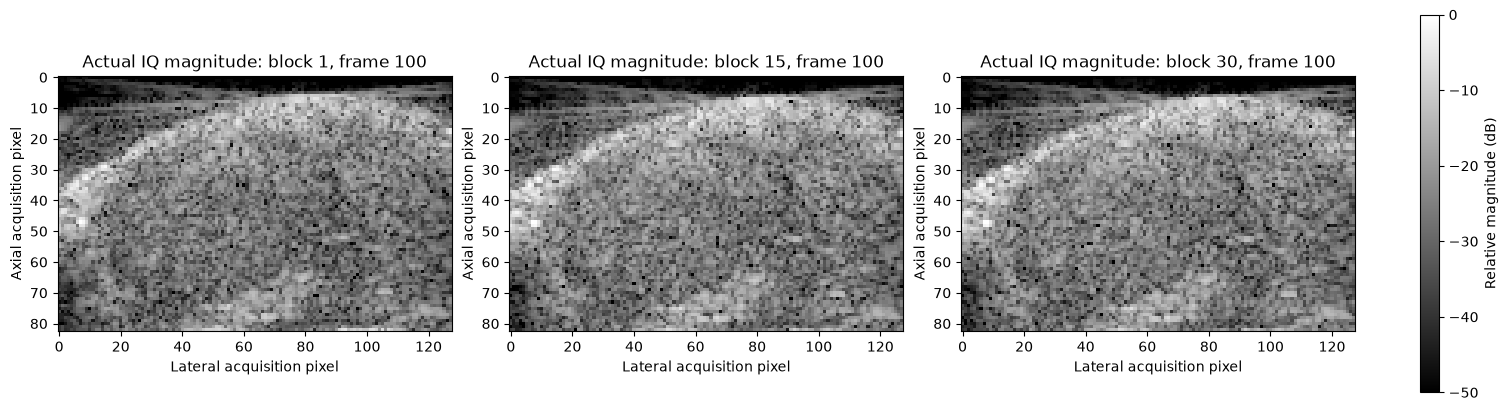

In [2]:
iq = load_observations()
print('Loaded block-first shape:', iq.shape, 'dtype:', iq.dtype)
print('Complete bound frames:', iq.shape[0] * iq.shape[-1])
assert iq.shape == (30, 83, 128, 200) and iq.dtype == np.complex64
assert np.isfinite(iq).all()
fig = plot_acquisition(iq)
display(fig)
plt.close(fig)

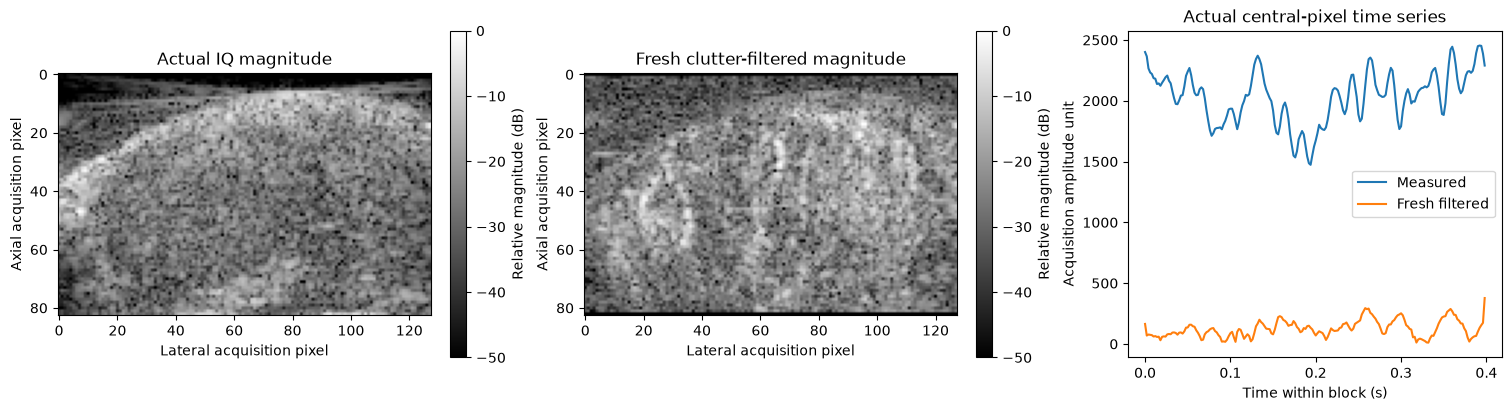

In [3]:
filtered_first = preprocess_block(iq[0])
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, array, title in zip(axes[:2], [iq[0, :, :, 99], filtered_first[:, :, 99]], ['Actual IQ magnitude', 'Fresh clutter-filtered magnitude']):
    value = np.abs(array)
    image = ax.imshow(20*np.log10(np.maximum(value / value.max(), 1e-5)), vmin=-50, vmax=0, cmap='gray')
    ax.set(title=title, xlabel='Lateral acquisition pixel', ylabel='Axial acquisition pixel')
    fig.colorbar(image, ax=ax, label='Relative magnitude (dB)')
axes[2].plot(np.arange(200)/500, np.abs(iq[0, 40, 64]), label='Measured')
axes[2].plot(np.arange(200)/500, np.abs(filtered_first[40, 64]), label='Fresh filtered')
axes[2].set(title='Actual central-pixel time series', xlabel='Time within block (s)', ylabel='Acquisition amplitude unit')
axes[2].legend()
display(fig)
plt.close(fig)

In [4]:
start = time.perf_counter()
fresh = reconstruct(iq, methods=METHODS, progress=lambda done, total: print(f'Fresh full acquisition: block {done}/{total}', flush=True))
fresh_runtime = time.perf_counter() - start
print('Fresh full three-method runtime (s):', fresh_runtime)
for method in METHODS:
    print(method, 'localizations:', int(fresh[method]['counts'][:, 0].sum()), 'retained tracks:', int(fresh[method]['counts'][:, 1].sum()))
with np.load('notebooks/reference_outputs/upstream.npz', allow_pickle=False) as archive:
    upstream = {key: archive[key] for key in archive.files}
with np.load('notebooks/reference_outputs/upstream_single_precision.npz', allow_pickle=False) as archive:
    native_single = {key: archive[key] for key in archive.files}
print('Upstream sources: independent Octave run on bound data; native-single and explicit double-computation run are distinct.')

Fresh full acquisition: block 1/30


Fresh full acquisition: block 2/30


Fresh full acquisition: block 3/30


Fresh full acquisition: block 4/30


Fresh full acquisition: block 5/30


...

Fresh full acquisition: block 28/30


Fresh full acquisition: block 29/30


Fresh full acquisition: block 30/30


Fresh full three-method runtime (s): 181.93048840004485
radial localizations: 1019468 retained tracks: 15622
wa localizations: 1068647 retained tracks: 15931
integer localizations: 1068647 retained tracks: 18107


Upstream sources: independent Octave run on bound data; native-single and explicit double-computation run are distinct.


In [5]:
table = []
for index, method in enumerate(METHODS):
    for quantity in ('density', 'speed'):
        value = metrics(fresh[method][quantity], upstream[quantity][:, :, index])
        table.append({'method': method, 'quantity': quantity, 'comparison': 'fresh local double vs upstream double', **value})
print(json.dumps(table, indent=2, allow_nan=False))
for row in table:
    ncc_limit, error_limit = (.995, .005) if row['quantity'] == 'density' else (.99, .01)
    assert row['ncc'] >= ncc_limit and row['nrmse'] <= error_limit, 'Frozen full-acquisition comparison gate failed'
print('Measured method stages: localization + assignment + trajectory processing + both renderings; shared preprocessing excluded.')
for index, method in enumerate(METHODS):
    print(method, 'fresh local stage seconds:', float(fresh[method]['method_runtime_seconds'].sum()), 'original Octave stage seconds:', float(upstream['runtimes'][:, index].sum()))
print('These are identified execution measurements on different software backends, not a hardware-matched reproduction of the paper runtime metric.')
print('Presentation table (rounding only for display):')
print('| Method | Quantity | NCC | Dynamic-range NRMSE |')
print('| --- | --- | ---: | ---: |')
for row in table:
    print(f"| {row['method']} | {row['quantity']} | {row['ncc']:.8f} | {row['nrmse']:.8g} |")
from evaluation.judge import evaluate
Path('output').mkdir(exist_ok=True)
np.savez_compressed('output/reconstruction.npz', reconstruction=fresh['radial']['density'][None], speed=fresh['radial']['speed'][None])
report, judge_code = evaluate('output/reconstruction.npz')
Path('output/judge_report.json').write_text(json.dumps(report, indent=2, allow_nan=False), encoding='utf-8')
print('Fresh radial submission:', json.dumps(report, indent=2))
assert judge_code == 0, 'Fresh required outputs must pass every declared metric'
assert all(len(fresh[m]['counts']) == 30 for m in METHODS)

[
  {
    "method": "radial",
    "quantity": "density",
    "comparison": "fresh local double vs upstream double",
    "ncc": 0.9999999999999998,
    "nrmse": 0.0
  },
  {
    "method": "radial",
    "quantity": "speed",
    "comparison": "fresh local double vs upstream double",
    "ncc": 1.0000000000000007,
    "nrmse": 6.397933061530497e-10
  },
  {
    "method": "wa",
    "quantity": "density",
    "comparison": "fresh local double vs upstream double",
    "ncc": 1.0,
    "nrmse": 0.0
  },
  {
    "method": "wa",
    "quantity": "speed",
    "comparison": "fresh local double vs upstream double",
    "ncc": 0.999999999999998,
    "nrmse": 4.826063194629155e-10
  },
  {
    "method": "integer",
    "quantity": "density",
    "comparison": "fresh local double vs upstream double",
    "ncc": 1.0000000000000002,
    "nrmse": 0.0
  },
  {
    "method": "integer",
    "quantity": "speed",
    "comparison": "fresh local double vs upstream double",
    "ncc": 0.999999999999999,
    "nrmse"

Fresh radial submission: {
  "status": "pass",
  "passed": true,
  "metrics": {
    "reconstruction_ncc": 1.0,
    "reconstruction_nrmse": 0.0,
    "speed_ncc": 0.9999999999999998,
    "speed_nrmse": 6.397933061530497e-10
  },
  "thresholds": {
    "reconstruction_ncc": {
      "comparison": ">=",
      "boundary": 0.995
    },
    "reconstruction_nrmse": {
      "comparison": "<=",
      "boundary": 0.005
    },
    "speed_ncc": {
      "comparison": ">=",
      "boundary": 0.99
    },
    "speed_nrmse": {
      "comparison": "<=",
      "boundary": 0.01
    }
  },
  "errors": []
}


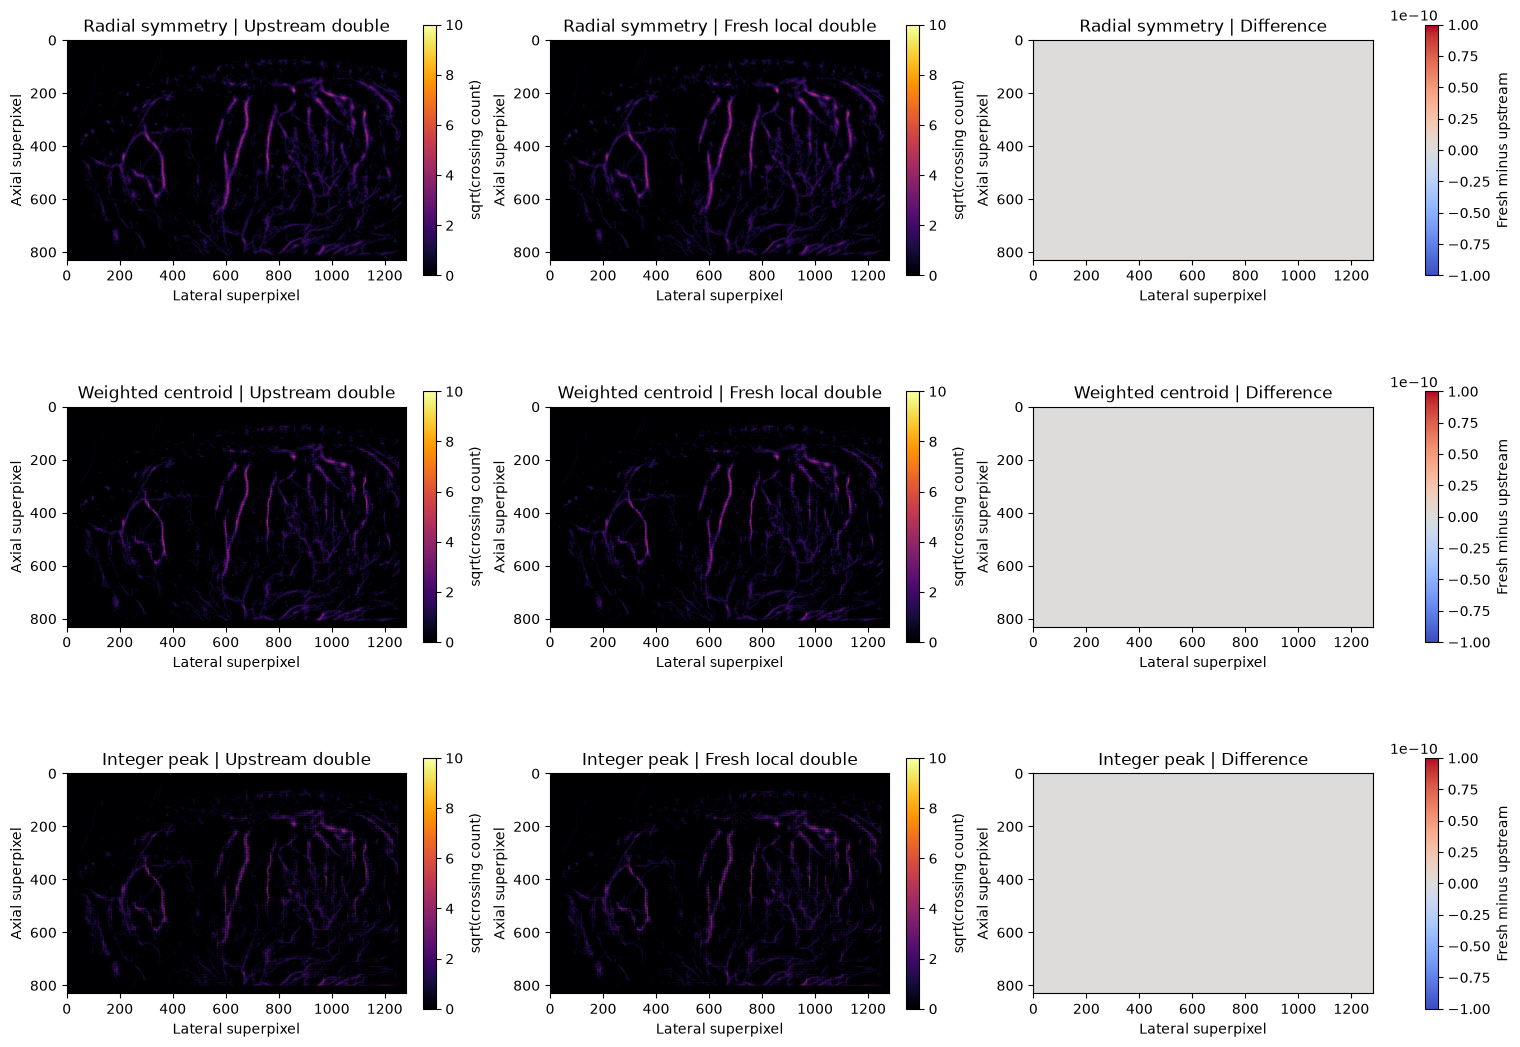

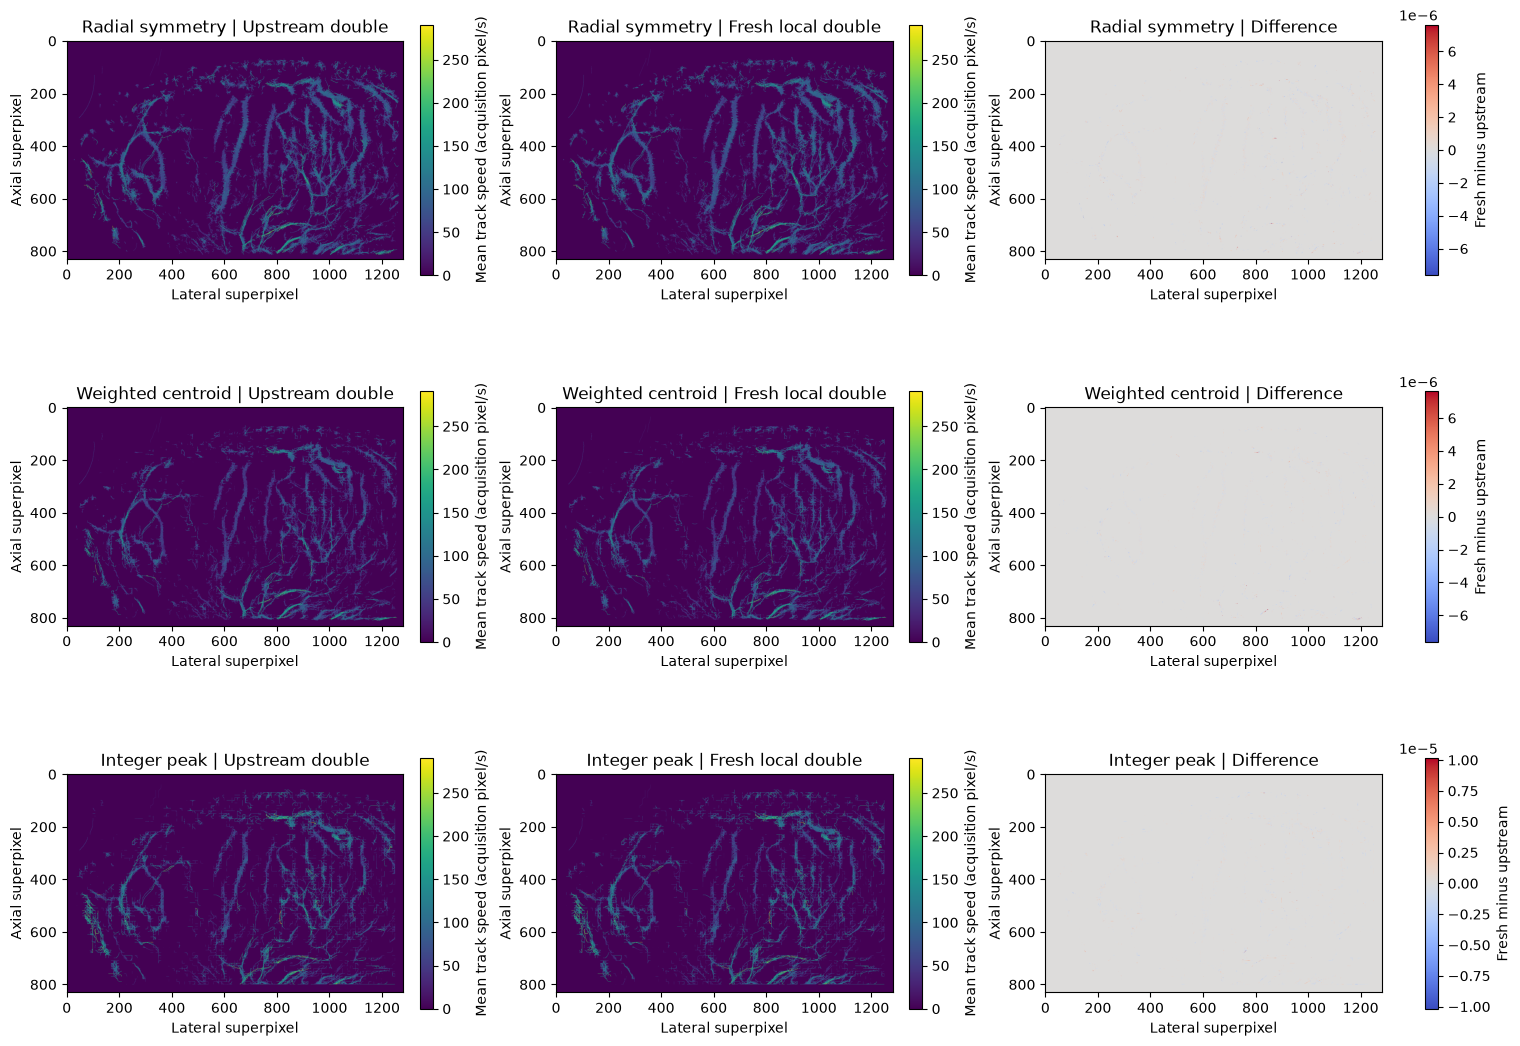

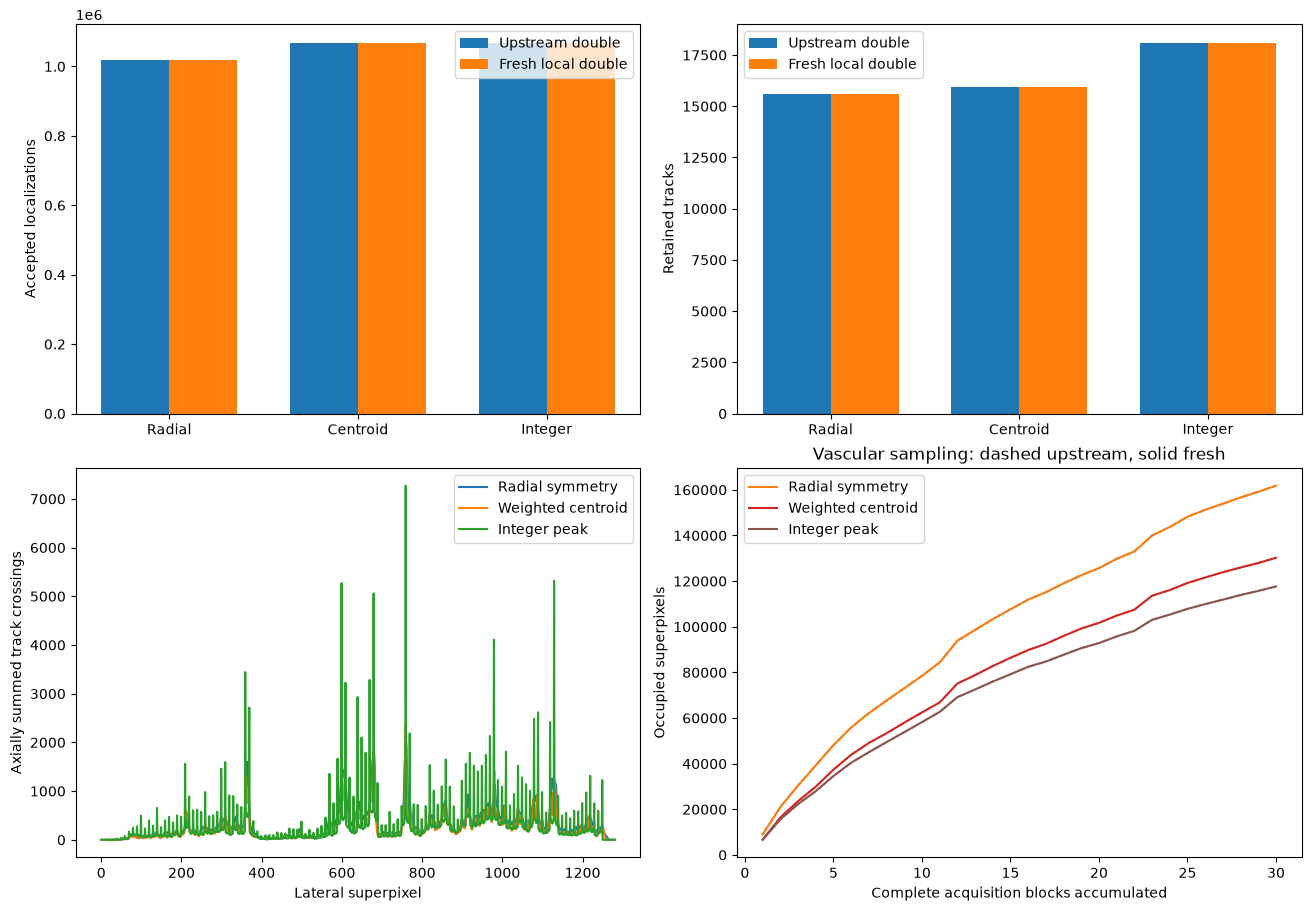

In [6]:
for fig in plot_comparisons(fresh, upstream):
    display(fig)
    plt.close(fig)
fig = plot_sampling(fresh, upstream)
display(fig)
plt.close(fig)

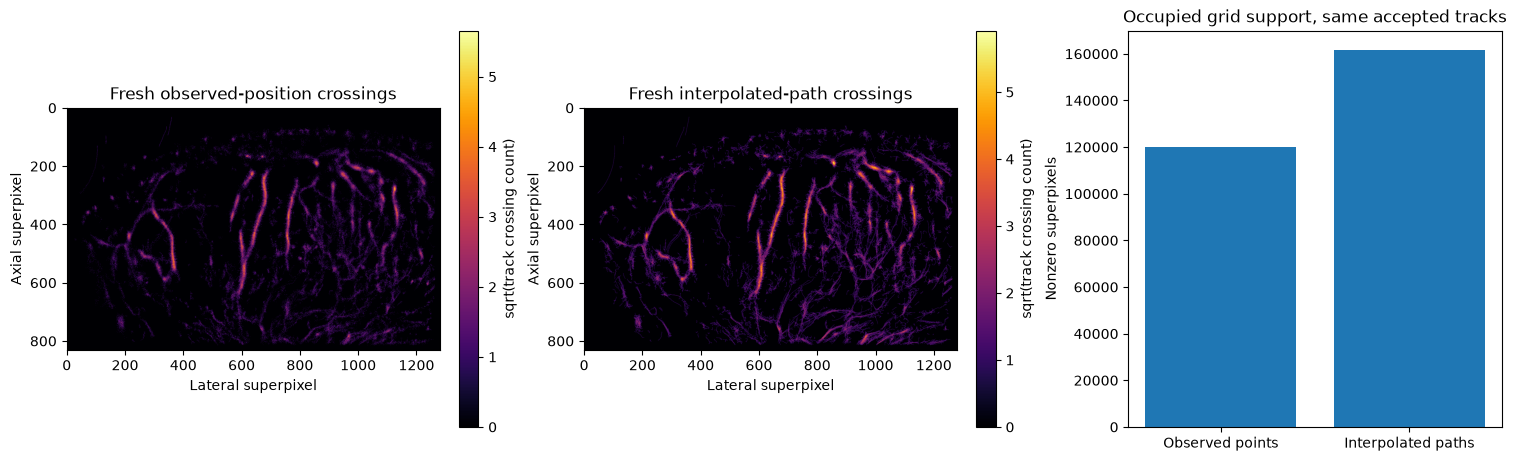

[
  {
    "method": "radial",
    "quantity": "density",
    "comparison": "upstream native single vs upstream double",
    "ncc": 0.9967402709064707,
    "nrmse": 0.003426786285687651
  },
  {
    "method": "radial",
    "quantity": "speed",
    "comparison": "upstream native single vs upstream double",
    "ncc": 0.9868533064839838,
    "nrmse": 0.02212023771125836
  },
  {
    "method": "wa",
    "quantity": "density",
    "comparison": "upstream native single vs upstream double",
    "ncc": 0.9980250360511476,
    "nrmse": 0.0018847660494711823
  },
  {
    "method": "wa",
    "quantity": "speed",
    "comparison": "upstream native single vs upstream double",
    "ncc": 0.990938929683856,
    "nrmse": 0.014169066800154756
  },
  {
    "method": "integer",
    "quantity": "density",
    "comparison": "upstream native single vs upstream double",
    "ncc": 0.9991120061362069,
    "nrmse": 0.0007998901767811608
  },
  {
    "method": "integer",
    "quantity": "speed",
    "comparison

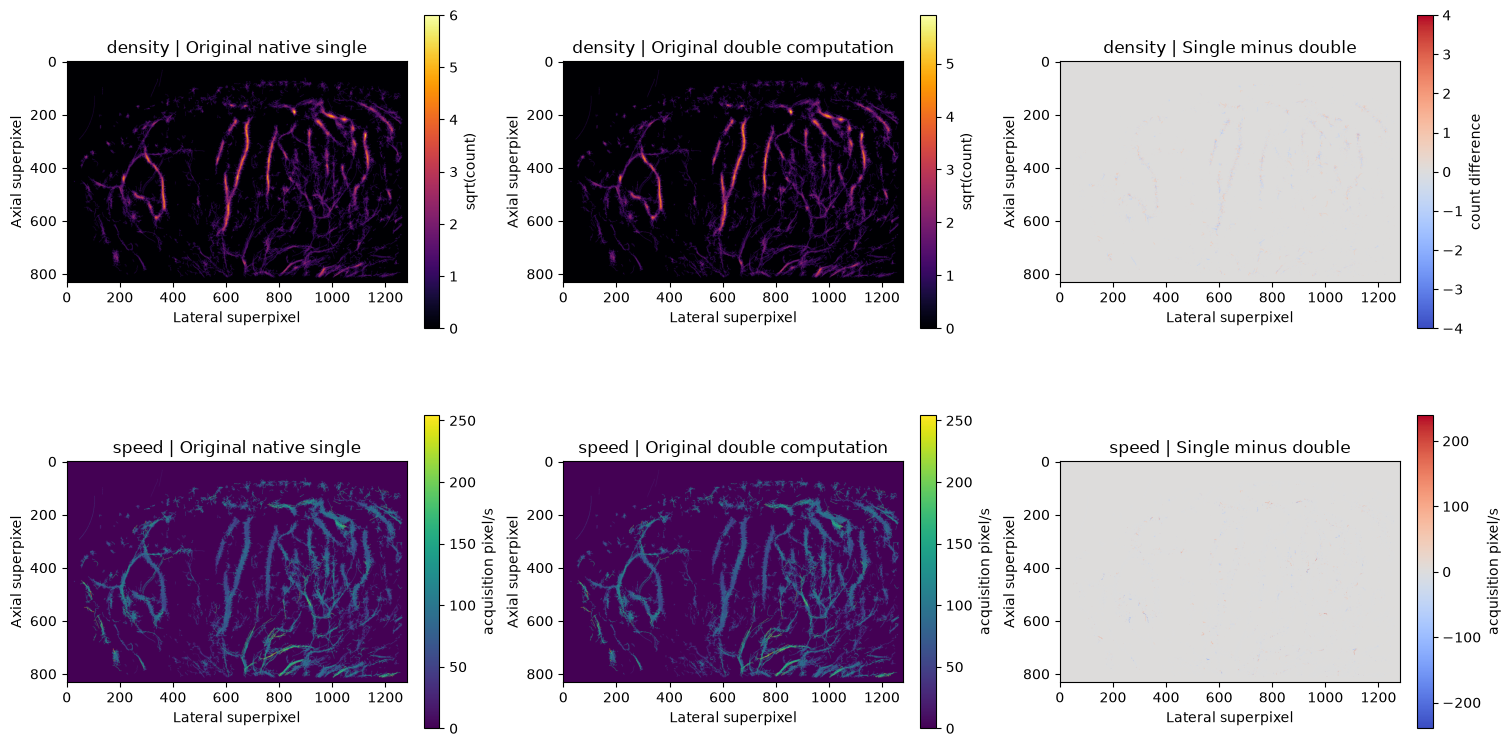

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for ax, array, title in zip(axes[:2], [fresh['radial']['nointerp'], fresh['radial']['density']], ['Fresh observed-position crossings', 'Fresh interpolated-path crossings']):
    image = ax.imshow(np.sqrt(array), cmap='inferno')
    ax.set(title=title, xlabel='Lateral superpixel', ylabel='Axial superpixel')
    fig.colorbar(image, ax=ax, label='sqrt(track crossing count)')
axes[2].bar(['Observed points', 'Interpolated paths'], [np.count_nonzero(fresh['radial']['nointerp']), np.count_nonzero(fresh['radial']['density'])])
axes[2].set(title='Occupied grid support, same accepted tracks', ylabel='Nonzero superpixels')
display(fig)
plt.close(fig)
precision_rows = []
for index, method in enumerate(METHODS):
    for quantity in ('density', 'speed'):
        precision_rows.append({'method': method, 'quantity': quantity, 'comparison': 'upstream native single vs upstream double', **metrics(native_single[quantity][:, :, index], upstream[quantity][:, :, index])})
print(json.dumps(precision_rows, indent=2, allow_nan=False))
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for row, quantity in enumerate(('density', 'speed')):
    single = native_single[quantity][:, :, 0]
    double = upstream[quantity][:, :, 0]
    for col, array in enumerate((single, double, single-double)):
        if col == 2:
            bound = max(float(np.max(np.abs(array))), 1e-10)
            image = axes[row, col].imshow(array, cmap='coolwarm', vmin=-bound, vmax=bound)
        else:
            image = axes[row, col].imshow(np.sqrt(array) if quantity == 'density' else array, cmap='inferno' if quantity == 'density' else 'viridis')
        axes[row, col].set(title=quantity + ' | ' + ['Original native single', 'Original double computation', 'Single minus double'][col], xlabel='Lateral superpixel', ylabel='Axial superpixel')
        fig.colorbar(image, ax=axes[row, col], shrink=.8, label='sqrt(count)' if quantity == 'density' and col < 2 else ('count difference' if quantity == 'density' else 'acquisition pixel/s'))
display(fig)
plt.close(fig)

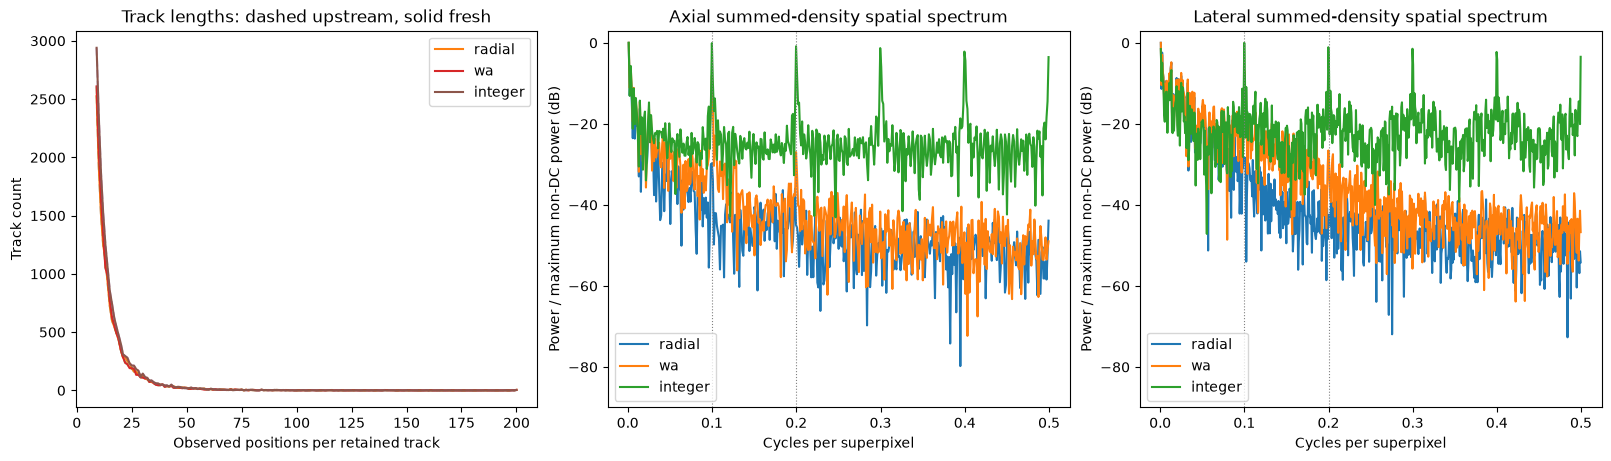

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)
for index, method in enumerate(METHODS):
    length = np.arange(201)
    axes[0].plot(length[9:], upstream['track_length_histogram'][9:, index], linestyle='--', alpha=.55)
    axes[0].plot(length[9:], fresh[method]['track_length_histogram'][9:], label=method)
    for axis, ax in zip((0, 1), axes[1:]):
        profile = fresh[method]['density'].sum(axis=1-axis)
        power = np.abs(np.fft.rfft(profile))**2
        frequency = np.fft.rfftfreq(len(profile))
        scale = max(float(power[1:].max()), np.finfo(float).tiny)
        ax.plot(frequency[1:], 10*np.log10(np.maximum(power[1:]/scale, 1e-12)), label=method)
axes[0].set(title='Track lengths: dashed upstream, solid fresh', xlabel='Observed positions per retained track', ylabel='Track count')
axes[0].legend()
for ax, label in zip(axes[1:], ['Axial', 'Lateral']):
    for harmonic in (.1, .2):
        ax.axvline(harmonic, color='gray', linewidth=.8, linestyle=':')
    ax.set(title=label + ' summed-density spatial spectrum', xlabel='Cycles per superpixel', ylabel='Power / maximum non-DC power (dB)', ylim=(-90, 3))
    ax.legend()
display(fig)
plt.close(fig)

## 6. Conclusion

The recorded comparisons support the selected double-computation extraction and expose its precision dependence. Finite bubble coverage, response overlap, association errors and the original finite-track speed bias remain; neither absolute mm/s flow nor a tenfold anatomical-resolution gain is demonstrated.


The active results above compare two required output quantities and all three localization methods on the complete bound real acquisition. The metric table, paired counts, upstream/fresh difference panels, and interpolation comparison provide separate evidence of numerical reproduction and of the method's spatial/temporal behavior. The native-single versus double comparison identifies a computation-precision issue rather than concealing it through weaker thresholds.

A faithful method reconstruction is not independently measured vascular truth. Thirty blocks sample only part of the full acquisition, and finite bubble coverage, overlapping responses, tissue/bubble temporal overlap, and assignment errors can affect the maps. The scalar path-speed estimator also retains the source's finite-track denominator and interpolation-endpoint bias. Because the beamformed spatial grid is not independently calibrated in mm, speed remains in acquisition pixel/s. A 10-fold display subdivision is not by itself an empirical claim of 10-fold anatomical resolution.

The fresh arrays, standalone Judge, independent original-source fixtures, physical/analytic checks, detailed plans, and provenance together support a reviewable computational task. They do not support unrestricted redistribution claims or clinical diagnostic conclusions.
